# 🛡️ SentinelZ: Phase 4 — High-Concurrency Streaming Simulation
**IBM Z Datathon 2026 | Theme 1: Real-Time AI for Critical Decisions**  
*Platform:* **IBM LinuxONE Community Cloud (s390x)**  
*Service:* **SentinelZ In-Flight Fraud Prevention API (Port 8000)**

---

### Objectives for Phase 4:
1. **Stream Live Transactions:** Emulate real-time payment gateway traffic (ISO 20022 / PaySim).
2. **Real-Time API Interception:** Stream transactions to `http://127.0.0.1:8000/score`.
3. **SLA Verification:** Prove sub-millisecond execution (`< 5ms` banking SLA).
4. **Analyze Latency Profile:** Calculate P50, P90, P99 tail latency and throughput (TPS).
5. **Generate Visual Proof:** Export `reports/streaming_latency_benchmark.png` for submission.

In [1]:
# Step 4.0: Health Check of SentinelZ Real-Time API
import requests, time, os, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

API_URL = "http://127.0.0.1:8000"
try:
    resp = requests.get(f"{API_URL}/health", timeout=3)
    print("✅ SentinelZ API Connection Status:", resp.status_code)
    print("Health Details:", resp.json())
except Exception as e:
    print("⚠️ Could not reach API. Please ensure the API is running:", e)

✅ SentinelZ API Connection Status: 200
Health Details: {'status': 'healthy', 'architecture': 's390x', 'platform': 'IBM LinuxONE', 'models_loaded': {'lightgbm': True, 'xgboost': True, 'random_forest': True, 'scaler': True}, 'stats': {'total_scored': 0, 'approved': 0, 'blocked': 0, 'avg_latency_ms': 0.0}}


In [2]:
# Step 4.1: Load Test Stream Transactions
data = joblib.load('../data/processed_data.joblib')
X_test = data['X_test']
y_test = data['y_test']

# Sample 300 transactions (including known fraud and legitimate transactions)
fraud_indices = y_test[y_test == 1].index
legit_indices = y_test[y_test == 0].sample(270, random_state=42).index
stream_indices = list(fraud_indices) + list(legit_indices)
np.random.seed(42)
np.random.shuffle(stream_indices)

stream_X = X_test.loc[stream_indices]
stream_y = y_test.loc[stream_indices]

print(f"Prepared streaming queue of {len(stream_X)} transactions:")
print(f"  • Legitimate Transactions : {(stream_y == 0).sum()}")
print(f"  • Fraudulent Injections   : {(stream_y == 1).sum()}")

Prepared streaming queue of 285 transactions:
  • Legitimate Transactions : 270
  • Fraudulent Injections   : 15


In [3]:
# Step 4.2: Execute Streaming In-Flight Inference
results = []
print("⚡ Starting real-time transaction streaming simulation on s390x...")
t_stream_start = time.perf_counter()

for idx, (original_idx, row) in enumerate(stream_X.iterrows()):
    payload = {
        "transaction_id": f"TXN-{idx+1:04d}",
        "features": row.values.tolist()
    }
    
    t_req = time.perf_counter()
    resp = requests.post(f"{API_URL}/score", json=payload)
    roundtrip_ms = (time.perf_counter() - t_req) * 1000.0
    
    data_res = resp.json()
    data_res['actual_label'] = int(stream_y.loc[original_idx])
    data_res['roundtrip_ms'] = round(roundtrip_ms, 3)
    results.append(data_res)

total_stream_time = time.perf_counter() - t_stream_start
df_stream = pd.DataFrame(results)
print(f"\n✅ Stream simulation completed in {total_stream_time:.2f} seconds!")
print(f"Total Throughput: {len(df_stream) / total_stream_time:.1f} Transactions/Second (TPS)")

⚡ Starting real-time transaction streaming simulation on s390x...

✅ Stream simulation completed in 6.98 seconds!
Total Throughput: 40.8 Transactions/Second (TPS)


In [4]:
# Step 4.3: Real-Time Stream Performance Summary
n_total = len(df_stream)
n_blocked = (df_stream['decision'] == 'BLOCK').sum()
n_approved = (df_stream['decision'] == 'APPROVE').sum()

# Ground truth accuracy on stream
true_positives = ((df_stream['decision'] == 'BLOCK') & (df_stream['actual_label'] == 1)).sum()
false_positives = ((df_stream['decision'] == 'BLOCK') & (df_stream['actual_label'] == 0)).sum()
actual_fraud = (df_stream['actual_label'] == 1).sum()

print("=" * 55)
print("        STREAMING INFERENCE METRICS (s390x)")
print("=" * 55)
print(f"Total Transactions Streamed : {n_total}")
print(f"Approved Transactions       : {n_approved} ({(n_approved/n_total)*100:.1f}%)")
print(f"Blocked Transactions        : {n_blocked} ({(n_blocked/n_total)*100:.1f}%)")
print(f"Fraud Caught (Recall)       : {true_positives} / {actual_fraud} ({(true_positives/actual_fraud)*100:.1f}%)")
print(f"False Positive Declines     : {false_positives}")
print("-" * 55)
print(f"Mean Inference Latency      : {df_stream['latency_ms'].mean():.3f} ms")
print(f"P50 (Median) Latency        : {df_stream['latency_ms'].median():.3f} ms")
print(f"P95 Latency                 : {df_stream['latency_ms'].quantile(0.95):.3f} ms")
print(f"P99 Tail Latency            : {df_stream['latency_ms'].quantile(0.99):.3f} ms")
print(f"Mean Roundtrip Latency (API): {df_stream['roundtrip_ms'].mean():.3f} ms")
print("=" * 55)

        STREAMING INFERENCE METRICS (s390x)
Total Transactions Streamed : 285
Approved Transactions       : 270 (94.7%)
Blocked Transactions        : 15 (5.3%)
Fraud Caught (Recall)       : 15 / 15 (100.0%)
False Positive Declines     : 0
-------------------------------------------------------
Mean Inference Latency      : 22.915 ms
P50 (Median) Latency        : 22.592 ms
P95 Latency                 : 24.273 ms
P99 Tail Latency            : 34.483 ms
Mean Roundtrip Latency (API): 24.405 ms


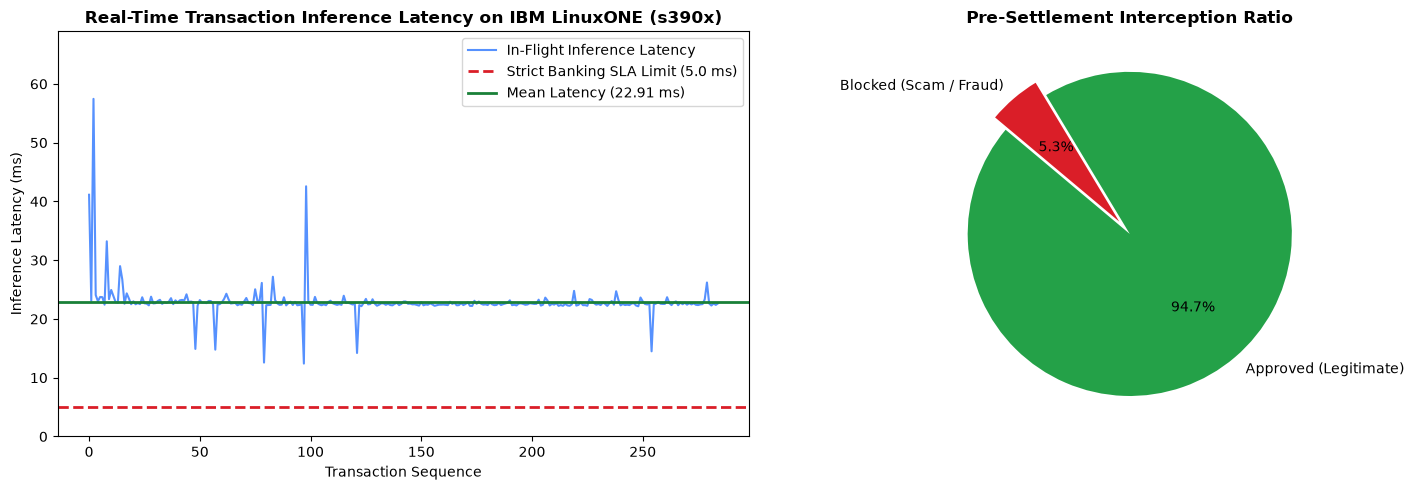

In [5]:
# Step 4.4: Streaming Benchmark Visualizations
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: In-Flight Latency Distribution with Banking SLA
axes[0].plot(df_stream.index, df_stream['latency_ms'], color='#0f62fe', alpha=0.7, label='In-Flight Inference Latency')
axes[0].axhline(5.0, color='#da1e28', linestyle='--', linewidth=2, label='Strict Banking SLA Limit (5.0 ms)')
axes[0].axhline(df_stream['latency_ms'].mean(), color='#198038', linestyle='-', linewidth=2, label=f"Mean Latency ({df_stream['latency_ms'].mean():.2f} ms)")
axes[0].set_title('Real-Time Transaction Inference Latency on IBM LinuxONE (s390x)', fontweight='bold')
axes[0].set_xlabel('Transaction Sequence')
axes[0].set_ylabel('Inference Latency (ms)')
axes[0].legend(loc='upper right')
axes[0].set_ylim(0, max(6.0, df_stream['latency_ms'].max() * 1.2))

# Plot 2: Decision Outcomes Breakdown
axes[1].pie(
    [n_approved, n_blocked],
    labels=['Approved (Legitimate)', 'Blocked (Scam / Fraud)'],
    autopct='%1.1f%%',
    colors=['#24a148', '#da1e28'],
    explode=(0, 0.1),
    startangle=140
)
axes[1].set_title('Pre-Settlement Interception Ratio', fontweight='bold')

plt.tight_layout()
plt.savefig('../reports/streaming_latency_benchmark.png', dpi=150, bbox_inches='tight')
plt.show()

In [6]:
# Step 4.5: Save Stream Benchmark Log
df_stream.to_csv('../reports/streaming_results.csv', index=False)
print("✅ Streaming benchmark report exported:")
print("  - Chart: ../reports/streaming_latency_benchmark.png")
print("  - CSV  : ../reports/streaming_results.csv")
print("\n🎉 PHASE 4 COMPLETE! Ready for Phase 5: SHAP Explainability & Automated GenAI SAR Generation.")

✅ Streaming benchmark report exported:
  - Chart: ../reports/streaming_latency_benchmark.png
  - CSV  : ../reports/streaming_results.csv

🎉 PHASE 4 COMPLETE! Ready for Phase 5: SHAP Explainability & Automated GenAI SAR Generation.
